In [22]:
import joblib # loads and saves model

In [24]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # sklearn is a library for ml

In [2]:
from sklearn.naive_bayes import MultinomialNB # Multinomial Naive Bayes algorithm from Scikit-learn

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer  # Imports tools for converting text to numerics

In [4]:
from sklearn.model_selection import train_test_split # Tools for splitting data for training and testing

In [25]:
import pandas as pd #library for data manipulation
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("spam.csv", encoding="latin-1")

# Preview
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [6]:
# Cleaning data
df = df.drop(columns = ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
df = df.rename(columns = {'v1': 'Label', 'v2': 'Message'})
df.head()

,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
# Check for missing values
print(df.isnull().sum())

Label      0
Message    0
dtype: int64


In [9]:
# Check for and drop duplicates 
print("Duplicates Before:", df.duplicated().sum())
df = df.drop_duplicates(keep='first')
print("Duplicates after:", df.duplicated().sum())

Duplicates Before: 403
Duplicates after: 0


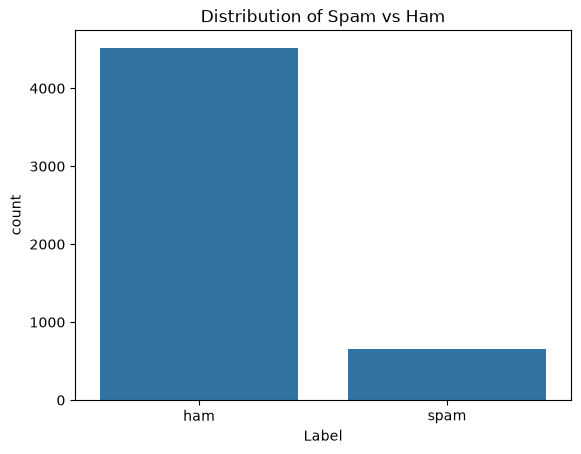

In [10]:
# Now plot the data
sns.countplot(x='Label', data=df)
plt.title('Distribution of Spam vs Ham')
plt.show()

In [11]:
# map 'ham' to 0 and 'spam' to 1

df['Label'] = df['Label'].map({'ham': 0, 'spam': 1})
df.head()

,Label,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [12]:
# Define Features(X) and Targets(Y)

x = df['Message']  #A Pandas data structure that stores values with an index and integrates with DataFrames and data-analysis operations
y = df['Label']
df.head()

,Label,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [13]:
# Train and test-split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2, # Reserve 20% for testing
    random_state = 42 # Make the random split reproducible
    )
# Check the shapes to make sure it worked
print("Training data size:", x_train.shape)
print("Testing data size:", x_test.shape)

Training data size: (4135,)
Testing data size: (1034,)


In [14]:
vectorizer = TfidfVectorizer()  # Creates a vectorizer object

x_train_vectorized = vectorizer.fit_transform(x_train) # learns vocabulary and IDF scores and converts those messages into numerical representations
x_test_vectorized = vectorizer.transform(x_test) # Applies the vocabulary and IDF scores to x_test from the messages


In [15]:
# AFTER VECTORIZATION AND TRAINING
model = MultinomialNB() # Created an instance of the algorithm
model.fit(x_train_vectorized, y_train) # Train the model


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3627., 508.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.13,-2.1 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 7657)","[[0. ,0. ,0.23,...,0. ,1. ,0.35], [1.56,4.26,0. ,...,0.28,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 7657)","[[-9.85,-9.85,-9.64,...,-9.85,-9.15,-9.55], [-8.26,-7.54,-9.2 ,...,-8.95,-9.2 ,-9.2 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7657


In [16]:
# PREDICTION

y_pred = model.predict(x_test_vectorized) # Make predictions using test messages, y_pred is what the model thinks the answers are y_test what the answers are actually

print("Actual labels:")
print(y_test.head(10).tolist())
print("Predicted labels:")
print(y_pred[:10])



Actual labels:
[0, 0, 0, 0, 0, 1, 0, 1, 0, 0]
Predicted labels:
[0 0 0 0 0 1 0 1 0 0]


In [17]:
# EVALUATION
#accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 95.55%


In [18]:
# classification
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97       889
           1       1.00      0.68      0.81       145

    accuracy                           0.96      1034
   macro avg       0.98      0.84      0.89      1034
weighted avg       0.96      0.96      0.95      1034



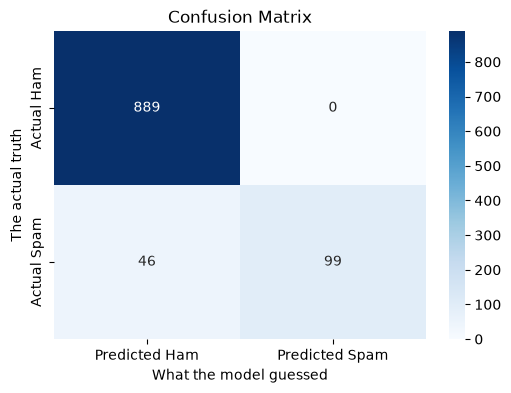

In [20]:
#confusion matrix marking the end of the evaluation process
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap = 'Blues',
           xticklabels=['Predicted Ham', 'Predicted Spam'], 
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.xlabel('What the model guessed')
plt.ylabel('The actual truth')
plt.title('Confusion Matrix')
plt.show()

In [23]:
# Save trained model to the computer's hard drive
joblib.dump(model, 'spam_model.pk1')

['spam_model.pk1']